# Тема 4. Парадокс ожидания

**Условие**

На лесном радио по кругу играют два трека на 2 и 8 минут. Паузы между ними нет. Енот включает радио в случайный момент. Какой шанс застать длинный трек? А если выбрать один из двух треков наугад? Сколько в среднем ждать до начала следующего трека?

![Енот в жёлтой шапке включает радио на деревянной веранде. Рядом висят часы.](enot_i_radio.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Расчёт

- Трек наугад — $1/2=50\%$.
- Момент наугад — $8/(2+8)=80\%$.

Среднее ожидание

$$E(W)=\frac{2}{10}\cdot\frac{2}{2}+\frac{8}{10}\cdot\frac{8}{2}=3{,}4\ \text{мин}.$$

[Парадокс инспекции](https://doi.org/10.1017/S0269964803171033)

## 2. Симуляция

In [2]:
sluch = np.random.default_rng(42)
n = 20_000

kor, dl = 2, 8
krug = kor + dl

trek = sluch.choice([kor, dl], n)
vremya = sluch.uniform(0, krug, n)
dlinnyi = vremya >= kor

p_trek = (trek == dl).mean()
p_vrem = dlinnyi.mean()
konec = np.where(dlinnyi, krug, kor)
zhdat = (konec - vremya).mean()

print(f'Трек наугад: {p_trek:.1%}')
print(f'Момент наугад: {p_vrem:.1%}')
print(f'Среднее ожидание: {zhdat:.2f} мин')

Трек наугад: 49.6%
Момент наугад: 80.3%
Среднее ожидание: 3.40 мин


## 3. Сравнение

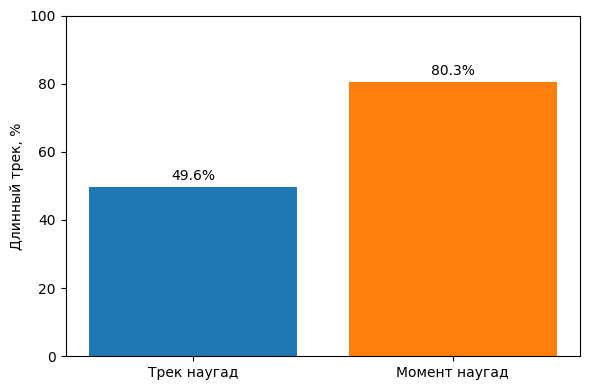

In [3]:
plt.figure(figsize=(6, 4))
stolb = plt.bar(['Трек наугад', 'Момент наугад'],
                [100 * p_trek, 100 * p_vrem],
                color=['tab:blue', 'tab:orange'])
plt.bar_label(stolb, fmt='%.1f%%', padding=3)
plt.ylabel('Длинный трек, %')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()